# Evaluation · saved experiments

Ten saved FNO and CNN runs, evaluated against catalog log-mass labels. No training, GPU or source FITS maps are needed. Paths are resolved from the repository root.

MAE and RMSE are measured in dex. The augmented split is a separate experiment group; see [evaluation protocol](../docs/results.md).


In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
    and (path / "src" / "galaxy_mass_estimation").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT / "src"))

## Imports


In [2]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "font.family": "DejaVu Sans",
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)

## Load the first experiment


In [3]:
targets = np.load(PROJECT_ROOT / "results/fno_base/raw/targets.npy")
preds = np.load(PROJECT_ROOT / "results/fno_base/raw/predictions.npy")

## Paired metrics and plots


In [4]:
def show_vis(targets, preds, title):
    """Plot paired predictions and residuals in log-mass space."""
    targets = np.asarray(targets).reshape(-1)
    preds = np.asarray(preds).reshape(-1)
    if targets.shape != preds.shape:
        raise ValueError("Targets and predictions must have the same shape")

    errors = preds - targets
    mae = np.abs(errors).mean()
    mse = np.square(errors).mean()
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
    fig.suptitle(title, fontsize=15, fontweight="bold")

    low = min(targets.min(), preds.min())
    high = max(targets.max(), preds.max())
    axes[0].scatter(targets, preds, s=9, alpha=0.3, color="#255b89", edgecolors="none")
    axes[0].plot(
        [low, high], [low, high], "--", color="#159b91", label="Perfect agreement"
    )
    axes[0].set(
        xlabel="Catalog log10(M500cUncorr)", ylabel="Predicted log10(M500cUncorr)"
    )
    axes[0].set_aspect("equal", adjustable="box")
    axes[0].legend(frameon=False)

    axes[1].hist(errors, bins=40, color="#255b89", alpha=0.85)
    axes[1].axvline(0, linestyle="--", color="#159b91")
    axes[1].set(
        xlabel="Prediction - target [dex]",
        ylabel="Test samples",
        title="Residual distribution",
    )
    for ax in axes:
        ax.grid(alpha=0.18)
        ax.spines[["top", "right"]].set_visible(False)
    plt.show()
    print(
        f"n={len(targets)} | MAE={mae:.4f} dex | RMSE={np.sqrt(mse):.4f} dex | MSE={mse:.6f} dex^2"
    )

## FNO base / raw


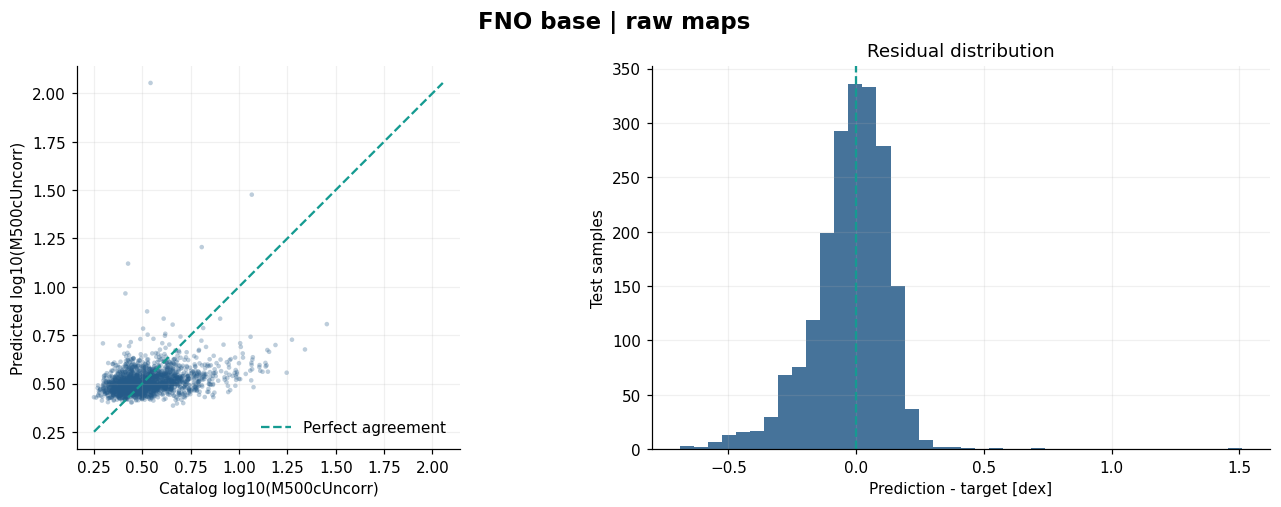

n=1994 | MAE=0.1105 dex | RMSE=0.1520 dex | MSE=0.023116 dex^2


In [5]:
show_vis(targets, preds, "FNO base | raw maps")

## FNO wide / raw


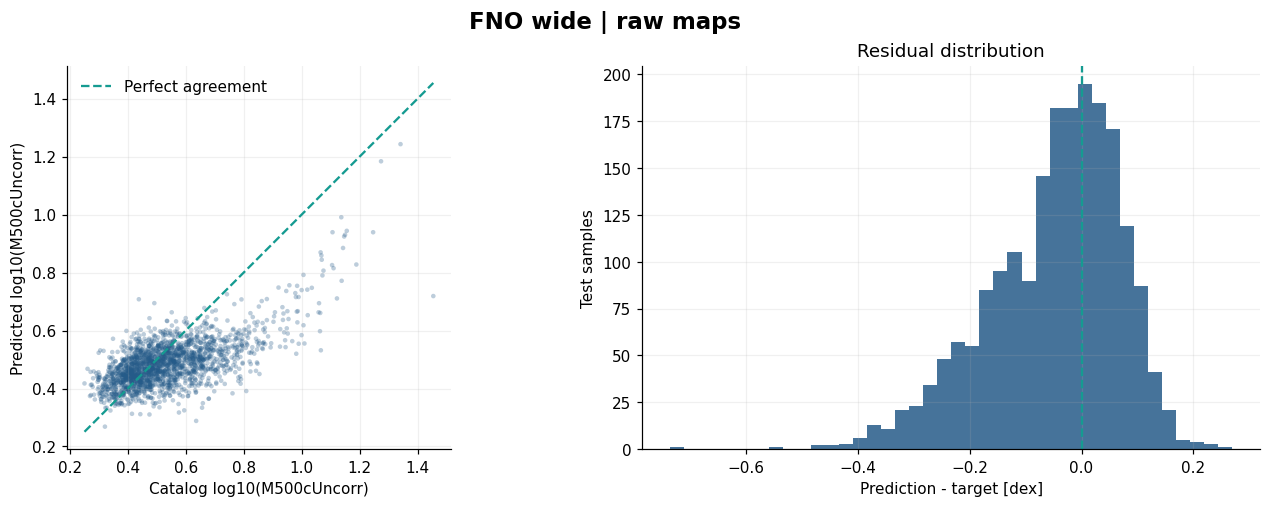

n=1994 | MAE=0.0956 dex | RMSE=0.1281 dex | MSE=0.016405 dex^2


In [6]:
targets = np.load(PROJECT_ROOT / "results/fno_wide/raw/targets.npy")
preds = np.load(PROJECT_ROOT / "results/fno_wide/raw/predictions.npy")

show_vis(targets, preds, "FNO wide | raw maps")

## FNO less / raw


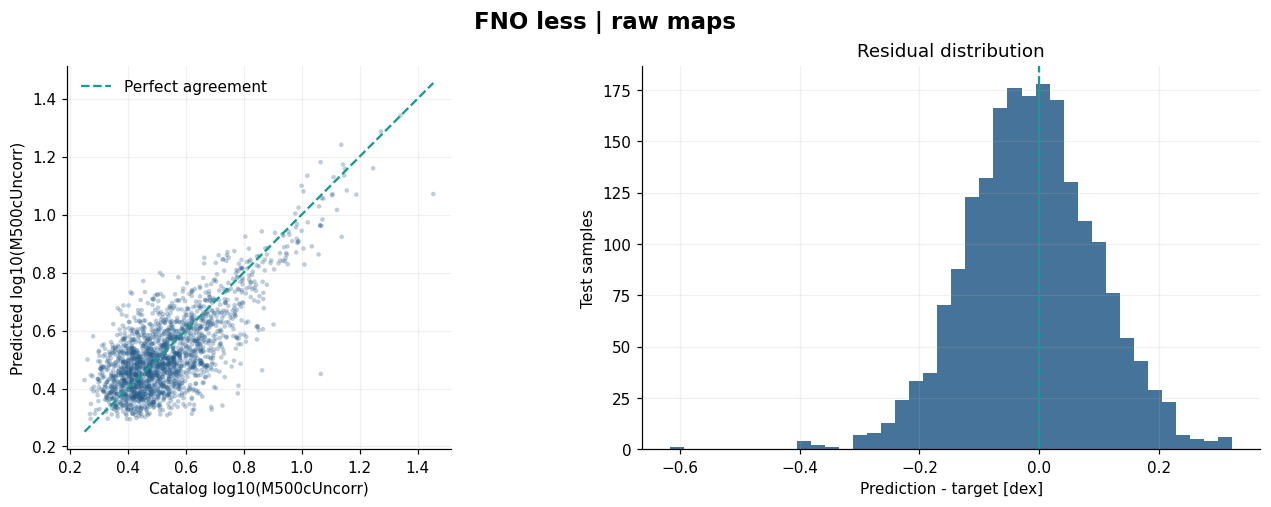

n=1994 | MAE=0.0859 dex | RMSE=0.1093 dex | MSE=0.011942 dex^2


In [7]:
targets = np.load(PROJECT_ROOT / "results/fno_less/raw/targets.npy")
preds = np.load(PROJECT_ROOT / "results/fno_less/raw/predictions.npy")
show_vis(targets, preds, "FNO less | raw maps")

## FNO base / normalized


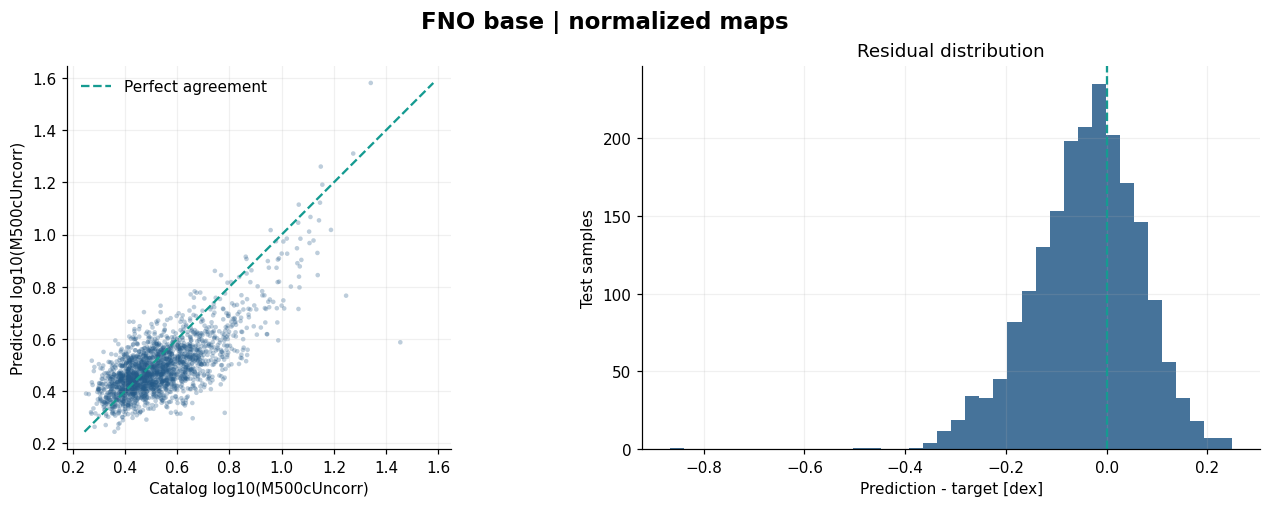

n=1994 | MAE=0.0876 dex | RMSE=0.1142 dex | MSE=0.013037 dex^2


In [8]:
targets = np.load(PROJECT_ROOT / "results/fno_base/normalized/targets.npy")
preds = np.load(PROJECT_ROOT / "results/fno_base/normalized/predictions.npy")
show_vis(targets, preds, "FNO base | normalized maps")

## FNO less / normalized


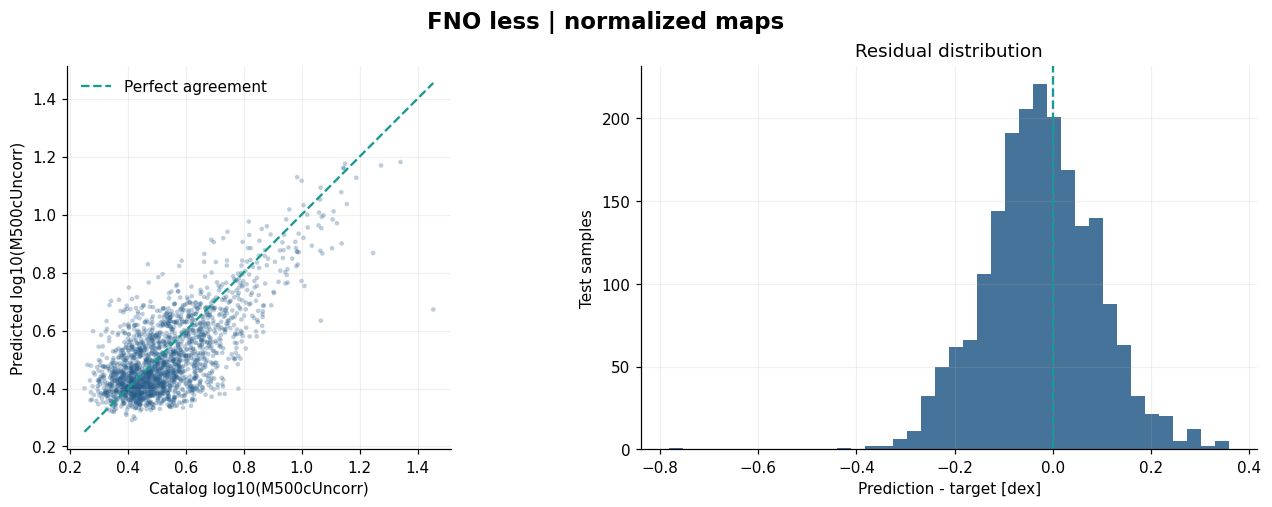

n=1994 | MAE=0.0911 dex | RMSE=0.1160 dex | MSE=0.013458 dex^2


In [9]:
targets = np.load(PROJECT_ROOT / "results/fno_less/normalized/targets.npy")
preds = np.load(PROJECT_ROOT / "results/fno_less/normalized/predictions.npy")
show_vis(targets, preds, "FNO less | normalized maps")

## FNO wide / normalized


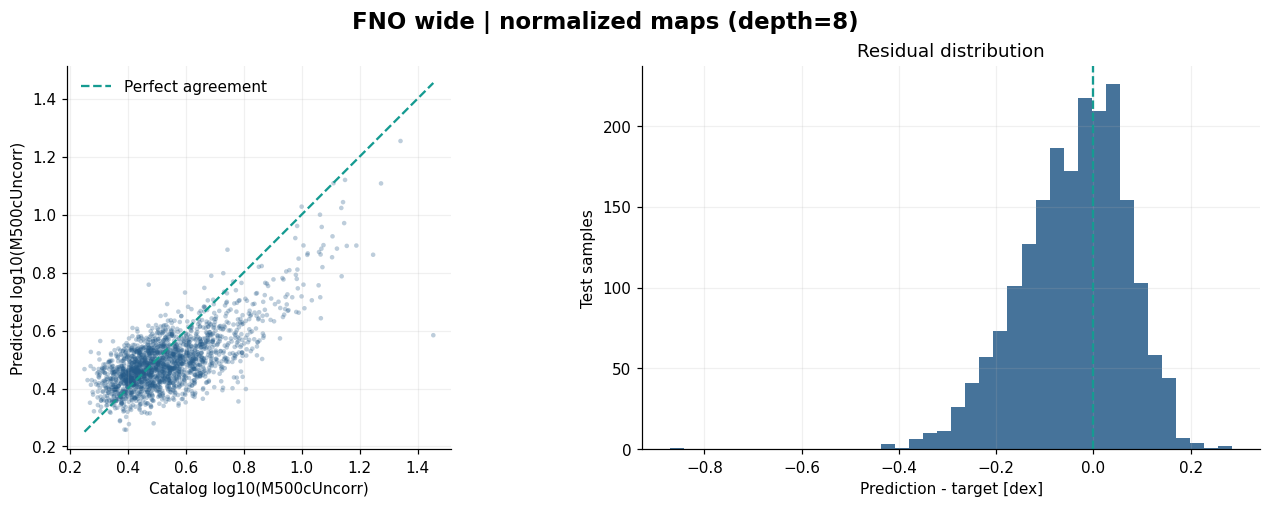

n=1994 | MAE=0.0899 dex | RMSE=0.1166 dex | MSE=0.013600 dex^2


In [10]:
targets = np.load(PROJECT_ROOT / "results/fno_wide/normalized/targets.npy")
preds = np.load(PROJECT_ROOT / "results/fno_wide/normalized/predictions.npy")
show_vis(targets, preds, "FNO wide | normalized maps (depth=8)")

## FNO wide / augmented


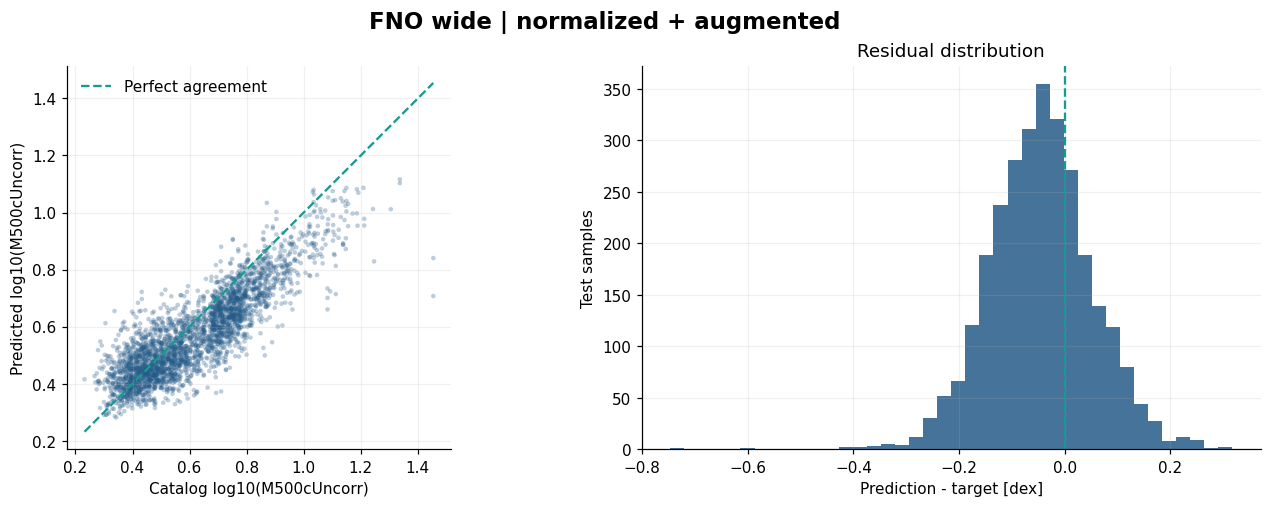

n=2894 | MAE=0.0849 dex | RMSE=0.1075 dex | MSE=0.011548 dex^2


In [11]:
targets = np.load(PROJECT_ROOT / "results/fno_wide/normalized_augmented/targets.npy")
preds = np.load(PROJECT_ROOT / "results/fno_wide/normalized_augmented/predictions.npy")
show_vis(targets, preds, "FNO wide | normalized + augmented")

## FNO less / augmented


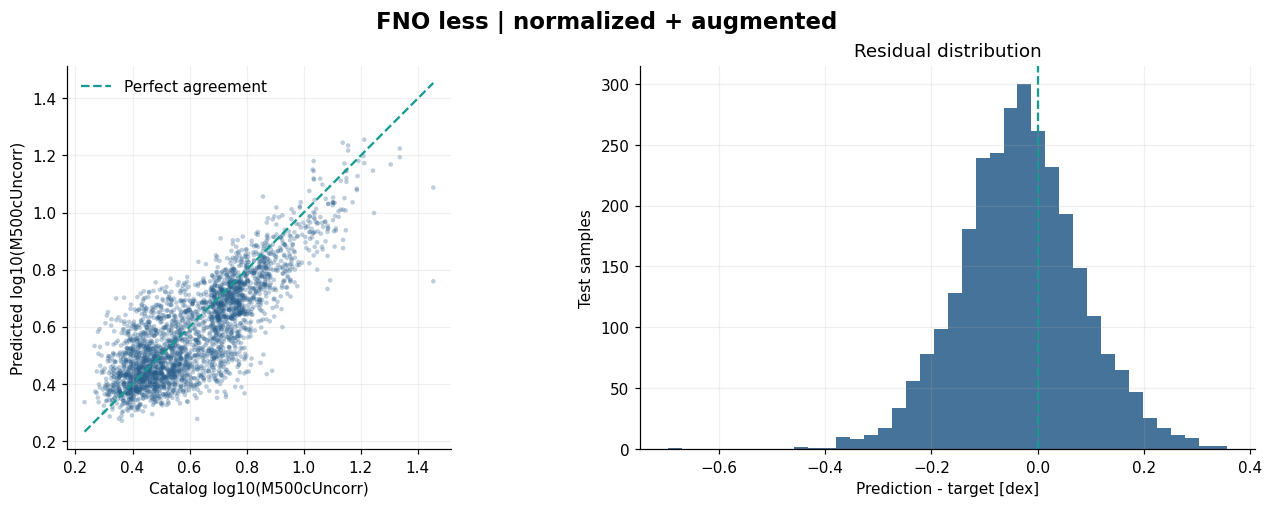

n=2894 | MAE=0.0934 dex | RMSE=0.1192 dex | MSE=0.014210 dex^2


In [12]:
targets = np.load(PROJECT_ROOT / "results/fno_less/normalized_augmented/targets.npy")
preds = np.load(PROJECT_ROOT / "results/fno_less/normalized_augmented/predictions.npy")
show_vis(targets, preds, "FNO less | normalized + augmented")

## FNO large / augmented


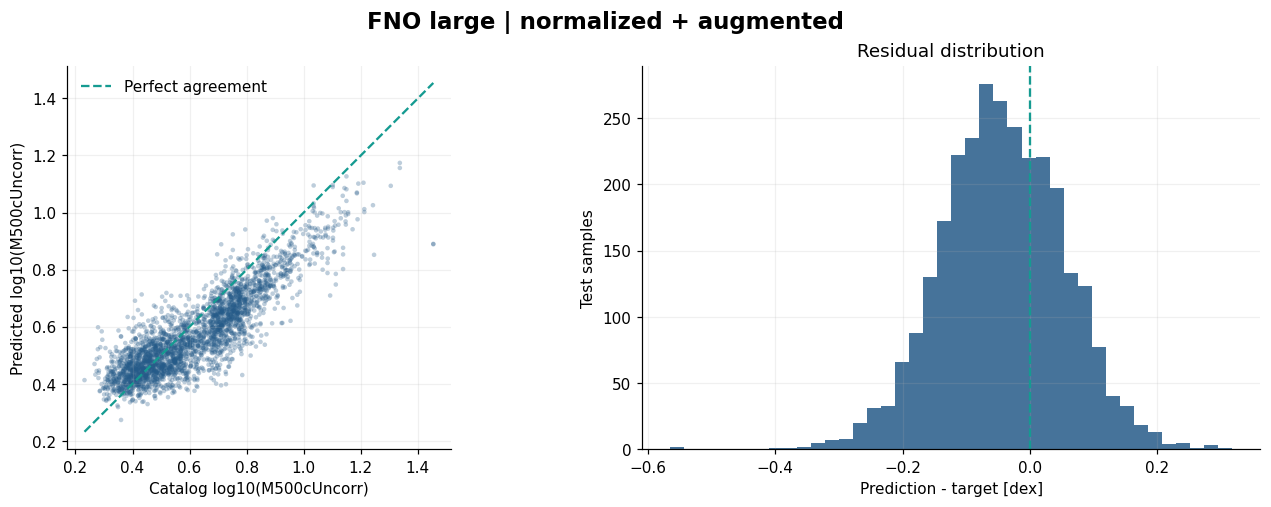

n=2894 | MAE=0.0845 dex | RMSE=0.1061 dex | MSE=0.011251 dex^2


In [13]:
targets = np.load(PROJECT_ROOT / "results/fno_large/normalized_augmented/targets.npy")
preds = np.load(PROJECT_ROOT / "results/fno_large/normalized_augmented/predictions.npy")
show_vis(targets, preds, "FNO large | normalized + augmented")

## CNN / augmented


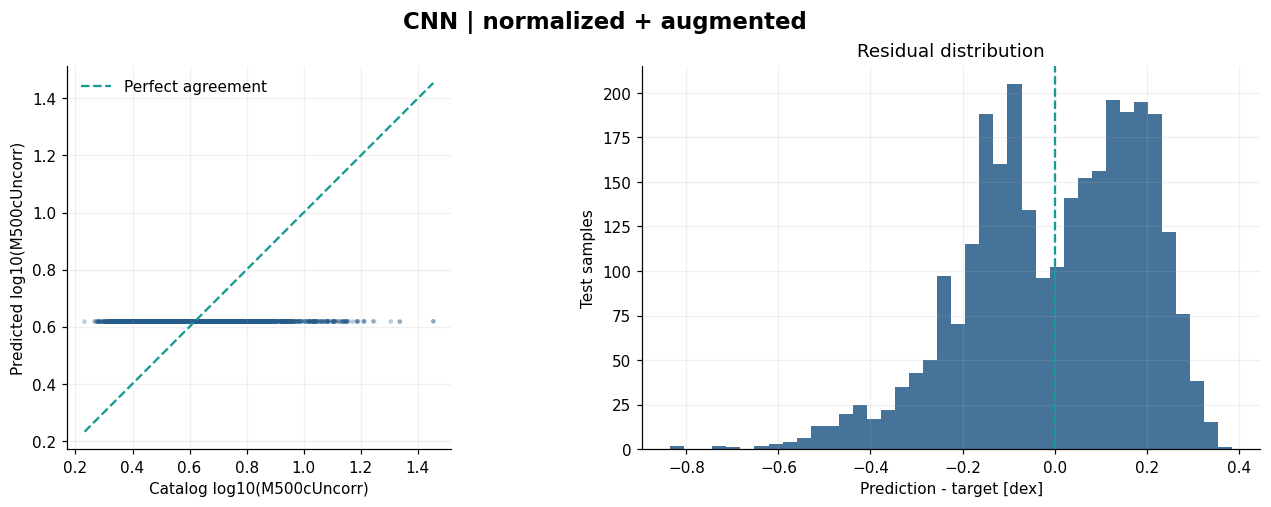

n=2894 | MAE=0.1600 dex | RMSE=0.1909 dex | MSE=0.036452 dex^2


In [14]:
targets = np.load(PROJECT_ROOT / "results/cnn/normalized_augmented/targets.npy")
preds = np.load(PROJECT_ROOT / "results/cnn/normalized_augmented/predictions.npy")
show_vis(targets, preds, "CNN | normalized + augmented")